# Data Quality Inspection – Sessions

## 1. Introduction

This notebook is dedicated to the systematic inspection and quality assessment of the TravelTide **Sessions** dataset.

The objective is to understand the structure, content, and overall quality of the dataset before proceeding with data cleaning, transformation, and further analysis.

The inspection focuses on the following aspects:

- **Dataset Structure:** Examine the number of rows, columns, column names, and data types.
- **Missing Values:** Identify and assess missing or null values.
- **Duplicate Records:** Detect potential duplicate rows and duplicate key values.
- **Value Distribution:** Review distinct values, value frequencies, and numerical ranges.
- **Data Consistency:** Identify inconsistencies, invalid values, and potential data quality issues.
- **Business Rules:** Check whether the data meets relevant logical and business requirements.

## 2. Inspection Approach

The project maintains two separate local data versions:

- **Original Data:** The original CSV files exported from the Neon PostgreSQL database. These files are preserved unchanged and serve as the reference dataset.
- **Working Copies:** Local copies of the original datasets, used for data inspection, quality assessment, and subsequent data preparation.

All inspection activities in this notebook are performed on the corresponding working copy.

During the inspection phase, neither the original data nor the working copies are modified. Identified data quality issues are documented and will be addressed in a separate data cleaning and preparation phase.

## 3. Expected Outcome

The inspection provides a structured overview of the dataset's quality and identifies potential issues that may affect subsequent analyses.

The findings will serve as the basis for defining appropriate data cleaning and transformation steps.

**Note:** This notebook is intended for data inspection and quality assessment only. No data modifications are performed.

## 4. General Table Overview

This section provides an initial overview of the Sessions dataset.

It examines the dataset dimensions, column names, data types, sample records, and memory usage to establish a general understanding of the table structure.

The results provide the foundation for the subsequent inspection of primary keys, foreign keys, data completeness, uniqueness, and data consistency.

In [84]:

# 4.1. General Table Overview

import pandas as pd
from pathlib import Path
import shutil

# Define project and working directories
PROJECT_DIR = Path.cwd().parent
WORKING_DIR = PROJECT_DIR / "data" / "working"

# 0. Create a new working copy from the original dataset
ORIGINAL_FILE = Path(
    r"D:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\input\original\public__sessions.csv"
)

WORKING_FILE = WORKING_DIR / "public__sessions.csv"

# Ensure the working directory exists
WORKING_DIR.mkdir(parents=True, exist_ok=True)

# Copy the original file to the working directory
shutil.copy2(ORIGINAL_FILE, WORKING_FILE)

print("Original dataset successfully copied to working directory.")
print(f"Source: {ORIGINAL_FILE}")
print(f"Working copy: {WORKING_FILE}")

# Load the Sessions working copy
sessions = pd.read_csv(WORKING_FILE)

# Display general dataset overview
print("=" * 70)
print("TRAVELTIDE – SESSIONS DATASET OVERVIEW")
print("=" * 70)

# 1. Display dataset dimensions
print("\n1. Dataset Dimensions")
print("-" * 70)
print(f"Number of rows: {sessions.shape[0]:,}")
print(f"Number of columns: {sessions.shape[1]}")

# 2. Display dataset information
print("\n2. Dataset Information")
print("-" * 70)
sessions.info()

# 3. Display descriptive statistics
print("\n3. Sessions Descriptive Statistics")
print("-" * 70)

display(
    sessions.describe(include="all").T.style
    .set_table_styles([
        {
            "selector": "th.row_heading",
            "props": [
                ("width", "55px"),
                ("min-width", "55px"),
                ("max-width", "55px"),
                ("white-space", "nowrap")
            ]
        },
        {
            "selector": "th.col_heading",
            "props": [
                ("max-width", "100px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("max-width", "100px"),
                ("white-space", "nowrap"),
                ("text-align", "right")
            ]
        }
    ])
)

# 4. Display first five records
print("\n4. First Five Records")
print("-" * 70)
display(sessions.head())

print("=" * 70)


Original dataset successfully copied to working directory.
Source: D:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\input\original\public__sessions.csv
Working copy: d:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\working\public__sessions.csv
TRAVELTIDE – SESSIONS DATASET OVERVIEW

1. Dataset Dimensions
----------------------------------------------------------------------
Number of rows: 5,408,063
Number of columns: 13

2. Dataset Information
----------------------------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 5408063 entries, 0 to 5408062
Data columns (total 13 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   session_id              str    
 1   user_id                 int64  
 2   trip_id                 str    
 3   session_start           str    
 4   session_end             str    
 5   flight_discount         str    
 6   hotel_discount          str    
 7   flight_discount_amount  float64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
session_id,5408063,5408063,275450-c9095461e19f482296686ee955f026dc,1,nan,nan,nan,nan,nan,nan,nan
user_id,5408063.000000,nan,nan,nan,398858.968933,270759.856949,0.000000,164327.000000,364172.000000,603152.000000,1020925.000000
trip_id,2335845,2245175,302383-e8b334feed8a483387fbd00955e42cb8,2,nan,nan,nan,nan,nan,nan,nan
session_start,5408063,960389,2023-03-27 20:46:00,50,nan,nan,nan,nan,nan,nan,nan
session_end,5408063,4868259,2023-03-26 11:23:37,8,nan,nan,nan,nan,nan,nan,nan
flight_discount,5408063,2,f,4431597,nan,nan,nan,nan,nan,nan,nan
hotel_discount,5408063,2,f,4626013,nan,nan,nan,nan,nan,nan,nan
flight_discount_amount,885796.000000,nan,nan,nan,0.139765,0.085191,0.050000,0.100000,0.100000,0.200000,0.850000
hotel_discount_amount,691380.000000,nan,nan,nan,0.110950,0.062021,0.050000,0.050000,0.100000,0.150000,0.650000
flight_booked,5408063,2,f,3416355,nan,nan,nan,nan,nan,nan,nan



4. First Five Records
----------------------------------------------------------------------


,session_id,user_id,trip_id,session_start,session_end,flight_discount,hotel_discount,flight_discount_amount,hotel_discount_amount,flight_booked,hotel_booked,page_clicks,cancellation
0,275450-c9095461e19f482296686ee955f026dc,275450,NaN,2023-06-22 16:27:00,2023-06-22 16:31:28,f,f,NaN,NaN,f,f,36,f
1,275473-f7d52afbbb7546c8ac5ada433abd6eb3,275473,NaN,2023-06-22 19:36:00,2023-06-22 19:36:16,t,f,0.25,NaN,f,f,2,f
2,275679-97b7e062a4b0493db934bf2921f39957,275679,275679-92558bc49db145cf915eb799096fc0c0,2023-06-22 14:05:00,2023-06-22 14:08:04,t,t,0.20,0.1,t,t,25,f
3,276121-c9d32570954f4d8d93f7bcc8de887007,276121,NaN,2023-06-22 15:14:00,2023-06-22 15:15:34,f,f,NaN,NaN,f,f,13,f
4,276181-5fe2c26c5e98418d8e784ae5013fc727,276181,NaN,2023-06-22 22:21:00,2023-06-22 22:21:16,f,f,NaN,NaN,f,f,2,f


In [85]:
# 4.2. Data Quality Inspection

# Identify numeric and datetime columns
numeric_columns = sessions.select_dtypes(include="number").columns

datetime_columns = [
    column for column in ["session_start", "session_end"]
    if column in sessions.columns
]

# Identify string columns
string_columns = sessions.select_dtypes(
    include=["object", "string"]
).columns

# Calculate minimum and maximum values
minimum_values = pd.Series(index=sessions.columns, dtype="object")
maximum_values = pd.Series(index=sessions.columns, dtype="object")

# Numeric columns
minimum_values[numeric_columns] = sessions[numeric_columns].min()
maximum_values[numeric_columns] = sessions[numeric_columns].max()

# Datetime columns
for column in datetime_columns:
    date_values = pd.to_datetime(
        sessions[column],
        errors="coerce"
    )

    minimum_values[column] = date_values.min()
    maximum_values[column] = date_values.max()

# Count empty and whitespace-only strings
empty_values = pd.Series(0, index=sessions.columns)

for column in string_columns:
    empty_values[column] = (
        sessions[column]
        .str.strip()
        .eq("")
        .sum()
    )

# Create data quality overview
data_quality = pd.DataFrame({
    "Data Type": sessions.dtypes.astype(str),
    "Minimum": minimum_values,
    "Maximum": maximum_values,
    "Missing Values": sessions.isna().sum(),
    "Empty Strings": empty_values,
    "Unique Values": sessions.nunique(dropna=True),
    "Duplicate Values": sessions.apply(
        lambda column: column.dropna().duplicated().sum()
    )
})

# Display data quality overview
print("=" * 110)
print("TRAVELTIDE – SESSIONS DATA QUALITY OVERVIEW")
print("=" * 110)

display(data_quality.style.set_table_styles([
    {
        "selector": "th.row_heading",
        "props": [
            ("width", "130px"),
            ("min-width", "130px"),
            ("white-space", "nowrap")
        ]
    },
    {
        "selector": "th.col_heading",
        "props": [
            ("min-width", "85px"),
            ("max-width", "130px"),
            ("white-space", "normal"),
            ("text-align", "center")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("min-width", "85px"),
            ("max-width", "130px"),
            ("white-space", "nowrap"),
            ("text-align", "right")
        ]
    }
]))

# Count rows containing at least one missing value
rows_with_missing = sessions.isna().any(axis=1).sum()

# Count completely duplicated rows
duplicate_rows = sessions.duplicated().sum()

print("\nAdditional Data Quality Checks")
print("-" * 110)

print(f"Rows containing missing values: "
      f"{rows_with_missing:,} of {len(sessions):,}")

print(f"Completely duplicated rows: {duplicate_rows:,}")

print("=" * 110)


TRAVELTIDE – SESSIONS DATA QUALITY OVERVIEW


,Data Type,Minimum,Maximum,Missing Values,Empty Strings,Unique Values,Duplicate Values
session_id,str,nan,nan,0,0,5408063,0
user_id,int64,0.000000,1020925.000000,0,0,1020926,4387137
trip_id,str,nan,nan,3072218,0,2245175,90670
session_start,str,2021-04-01 00:42:00,2023-07-28 23:57:55,0,0,960389,4447674
session_end,str,2021-04-01 00:43:40,2023-07-29 01:57:55,0,0,4868259,539804
flight_discount,str,nan,nan,0,0,2,5408061
hotel_discount,str,nan,nan,0,0,2,5408061
flight_discount_amount,float64,0.050000,0.850000,4522267,0,16,885780
hotel_discount_amount,float64,0.050000,0.650000,4716683,0,13,691367
flight_booked,str,nan,nan,0,0,2,5408061



Additional Data Quality Checks
--------------------------------------------------------------------------------------------------------------
Rows containing missing values: 5,349,170 of 5,408,063
Completely duplicated rows: 0


In [86]:
# Identify numeric and datetime columns
numeric_columns = sessions.select_dtypes(include="number").columns

datetime_columns = ["session_start", "session_end"]

# Initialize minimum and maximum values
minimum_values = pd.Series(index=sessions.columns, dtype="object")
maximum_values = pd.Series(index=sessions.columns, dtype="object")

# Calculate minimum and maximum for numeric columns
minimum_values[numeric_columns] = sessions[numeric_columns].min()
maximum_values[numeric_columns] = sessions[numeric_columns].max()

# Calculate minimum and maximum for session timestamps
for column in datetime_columns:
    if column in sessions.columns:
        date_values = pd.to_datetime(sessions[column], errors="coerce")
        minimum_values[column] = date_values.min()
        maximum_values[column] = date_values.max()

# Create data quality overview
data_quality = pd.DataFrame({
    "Data Type": sessions.dtypes.astype(str),
    "Minimum": minimum_values,
    "Maximum": maximum_values,
    "NaN": sessions.isna().sum(),
    "isnull": sessions.isnull().sum(),
    "Empty ('')": sessions.eq("").sum(),
    "Unique": sessions.nunique(dropna=True),
    "Duplicates": sessions.apply(
        lambda column: column.dropna().duplicated().sum()
    )
})


In [87]:
# Data Quality Inspection – Summary

print("\n" + "=" * 70)
print("DATA QUALITY INSPECTION – SUMMARY")
print("=" * 70)

print(f"Total records: {len(sessions):,}")
print(f"Total columns: {len(sessions.columns):,}")

print(f"Missing values: {sessions.isna().sum().sum():,}")
print(f"Empty strings: {empty_values.sum():,}")
print(f"Completely duplicated rows: {duplicate_rows:,}")

print("\nColumns with missing values:")

missing_summary = sessions.isna().sum()
missing_summary = missing_summary[missing_summary > 0]

if missing_summary.empty:
    print("No missing values found.")
else:
    print(missing_summary.to_string())

print("\n" + "=" * 70)



DATA QUALITY INSPECTION – SUMMARY
Total records: 5,408,063
Total columns: 13
Missing values: 12,311,168
Empty strings: 0
Completely duplicated rows: 0

Columns with missing values:
trip_id                   3072218
flight_discount_amount    4522267
hotel_discount_amount     4716683



In [88]:
data_quality


,Data Type,Minimum,Maximum,NaN,isnull,Empty (''),Unique,Duplicates
session_id,str,NaN,NaN,0,0,0,5408063,0
user_id,int64,0.0,1020925.0,0,0,0,1020926,4387137
trip_id,str,NaN,NaN,3072218,3072218,0,2245175,90670
session_start,str,2021-04-01 00:42:00,2023-07-28 23:57:55,0,0,0,960389,4447674
session_end,str,2021-04-01 00:43:40,2023-07-29 01:57:55,0,0,0,4868259,539804
flight_discount,str,NaN,NaN,0,0,0,2,5408061
hotel_discount,str,NaN,NaN,0,0,0,2,5408061
flight_discount_amount,float64,0.05,0.85,4522267,4522267,0,16,885780
hotel_discount_amount,float64,0.05,0.65,4716683,4716683,0,13,691367
flight_booked,str,NaN,NaN,0,0,0,2,5408061


## 4.3. Key Integrity & Temporal Consistency

This section examines the uniqueness and completeness of key identifiers and validates the temporal consistency of session timestamps.

The inspection focuses on:

- Primary Key Integrity: Check whether session identifiers are unique and complete.
- Foreign Key Completeness: Identify missing user identifiers.
- Timestamp Validity: Detect invalid session timestamps.
- Temporal Consistency: Check whether session end timestamps occur after session start timestamps.
- Session Duration: Identify potentially invalid session durations.

In [89]:
# 4.3. Key Integrity & Temporal Consistency

print("=" * 90)
print("TRAVELTIDE – SESSIONS KEY & TEMPORAL INTEGRITY")
print("=" * 90)

# 1. Primary Key Integrity
print("\n1. Primary Key Integrity")
print("-" * 90)

if "session_id" in sessions.columns:

    missing_session_ids = sessions["session_id"].isna().sum()

    duplicate_session_ids = sessions["session_id"].duplicated(
        keep=False
    ).sum()

    print(f"Missing session IDs: {missing_session_ids:,}")
    print(f"Rows with duplicate session IDs: {duplicate_session_ids:,}")

else:
    print("WARNING: session_id column not found.")

# 2. Foreign Key Completeness
print("\n2. Foreign Key Completeness")
print("-" * 90)

if "user_id" in sessions.columns:

    missing_user_ids = sessions["user_id"].isna().sum()

    print(f"Missing user IDs: {missing_user_ids:,}")

else:
    print("WARNING: user_id column not found.")

# 3. Timestamp Validity
print("\n3. Timestamp Validity")
print("-" * 90)

parsed_dates = {}

for column in ["session_start", "session_end"]:

    if column in sessions.columns:

        parsed_dates[column] = pd.to_datetime(
            sessions[column],
            errors="coerce"
        )

        invalid_dates = (
            sessions[column].notna()
            & parsed_dates[column].isna()
        ).sum()

        print(f"{column} – Invalid timestamps: {invalid_dates:,}")

# 4. Temporal Consistency
print("\n4. Temporal Consistency")
print("-" * 90)

if all(
    column in parsed_dates
    for column in ["session_start", "session_end"]
):

    start = parsed_dates["session_start"]
    end = parsed_dates["session_end"]

    negative_duration = (
        start.notna()
        & end.notna()
        & (end < start)
    ).sum()

    zero_duration = (
        start.notna()
        & end.notna()
        & (end == start)
    ).sum()

    print(f"Sessions with negative duration: {negative_duration:,}")
    print(f"Sessions with zero duration: {zero_duration:,}")

    # Calculate valid session durations
    valid_duration = (
        start.notna()
        & end.notna()
        & (end >= start)
    )

    session_duration = (
        end[valid_duration] - start[valid_duration]
    )

    print("\nSession Duration Statistics")
    print("-" * 90)

    if not session_duration.empty:

        print(f"Minimum duration: {session_duration.min()}")
        print(f"Maximum duration: {session_duration.max()}")
        print(f"Average duration: {session_duration.mean()}")

print("=" * 90)


TRAVELTIDE – SESSIONS KEY & TEMPORAL INTEGRITY

1. Primary Key Integrity
------------------------------------------------------------------------------------------
Missing session IDs: 0
Rows with duplicate session IDs: 0

2. Foreign Key Completeness
------------------------------------------------------------------------------------------
Missing user IDs: 0

3. Timestamp Validity
------------------------------------------------------------------------------------------
session_start – Invalid timestamps: 0
session_end – Invalid timestamps: 36,885

4. Temporal Consistency
------------------------------------------------------------------------------------------
Sessions with negative duration: 0
Sessions with zero duration: 0

Session Duration Statistics
------------------------------------------------------------------------------------------
Minimum duration: 0 days 00:00:01
Maximum duration: 0 days 02:00:00
Average duration: 0 days 00:03:12.621177


In [90]:
# Key Integrity & Temporal Consistency – Summary

print("\n" + "=" * 70)
print("KEY INTEGRITY & TEMPORAL CONSISTENCY – SUMMARY")
print("=" * 70)

# Primary Key
if "session_id" in sessions.columns:
    print(f"Missing session IDs: {missing_session_ids:,}")
    print(f"Rows with duplicate session IDs: {duplicate_session_ids:,}")

# Foreign Key
if "user_id" in sessions.columns:
    print(f"Missing user IDs: {missing_user_ids:,}")

# Timestamp validity
for column in parsed_dates:
    invalid_dates = (
        sessions[column].notna()
        & parsed_dates[column].isna()
    ).sum()

    print(f"Invalid {column} timestamps: {invalid_dates:,}")

# Temporal consistency
if all(
    column in parsed_dates
    for column in ["session_start", "session_end"]
):
    print(f"Negative session durations: {negative_duration:,}")
    print(f"Zero session durations: {zero_duration:,}")

print("=" * 70)



KEY INTEGRITY & TEMPORAL CONSISTENCY – SUMMARY
Missing session IDs: 0
Rows with duplicate session IDs: 0
Missing user IDs: 0
Invalid session_start timestamps: 0
Invalid session_end timestamps: 36,885
Negative session durations: 0
Zero session durations: 0


## 4.4. Monthly Session Activity

This section analyzes the monthly distribution of sessions based on the session_start timestamp.

The analysis covers the entire observation period, from the month of the first recorded session to the month of the last recorded session.

The objective is to identify monthly activity patterns, seasonal trends and changes in platform usage over time.

TRAVELTIDE – MONTHLY SESSION ACTIVITY
First session: 2021-04-01 00:42:00
Last session:  2023-07-28 23:57:55
Total sessions: 5,408,063
Total months: 28


,Number of Sessions
session_start,
2021-04-01,1389
2021-05-01,5267
2021-06-01,20987
2021-07-01,37279
2021-08-01,44779
2021-09-01,28652
2021-10-01,30661
2021-11-01,50251
2021-12-01,54796


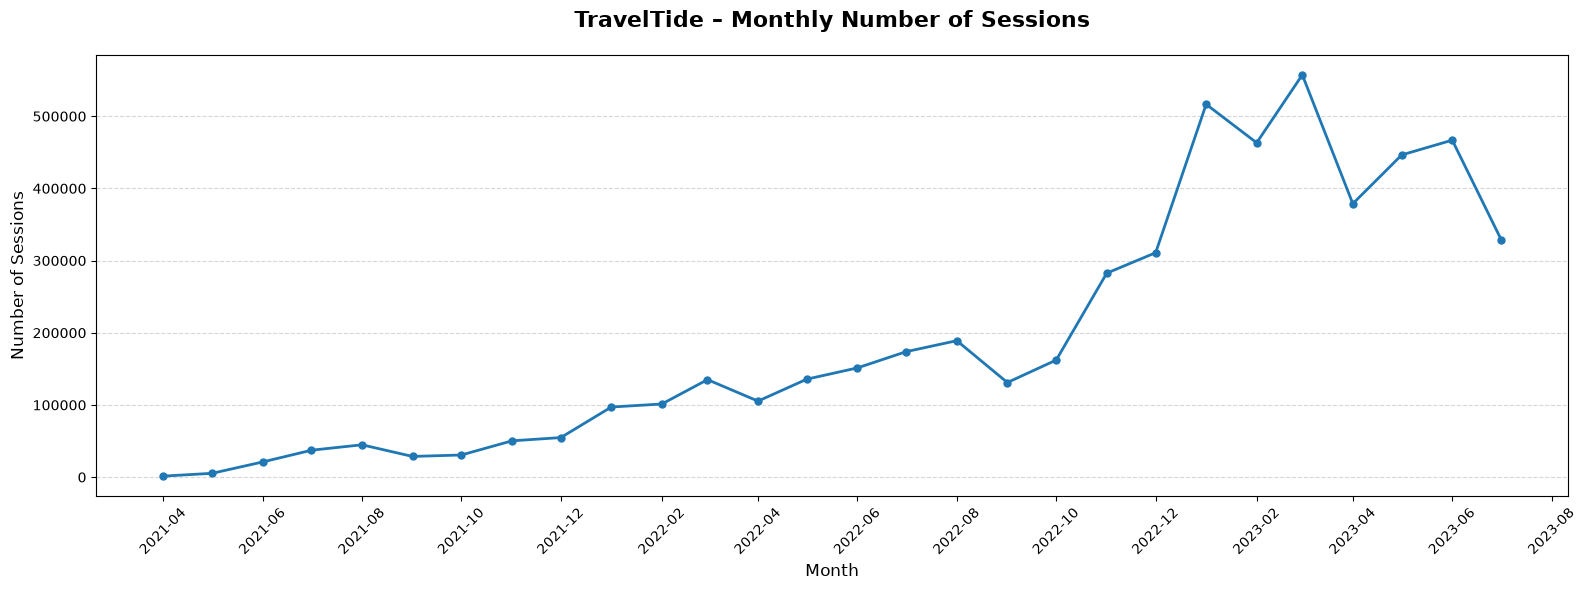

In [91]:
# 4.4. Monthly Session Activity

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Convert session_start to datetime
sessions["session_start"] = pd.to_datetime(
    sessions["session_start"],
    errors="coerce"
)

# Remove records without valid session_start
valid_sessions = sessions.dropna(
    subset=["session_start"]
).copy()

# Set session_start as index
valid_sessions = valid_sessions.set_index("session_start")

# Aggregate sessions by month
monthly_sessions = (
    valid_sessions
    .resample("MS")
    .size()
)

# Create a complete monthly timeline
# Missing months are filled with zero
monthly_sessions = monthly_sessions.asfreq(
    "MS",
    fill_value=0
)

# Display monthly session counts
monthly_summary = monthly_sessions.rename(
    "Number of Sessions"
).to_frame()

print("=" * 70)
print("TRAVELTIDE – MONTHLY SESSION ACTIVITY")
print("=" * 70)

print(f"First session: {valid_sessions.index.min()}")
print(f"Last session:  {valid_sessions.index.max()}")
print(f"Total sessions: {len(valid_sessions):,}")
print(f"Total months: {len(monthly_sessions)}")

display(monthly_summary)

# Create timeline visualization
fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(
    monthly_sessions.index,
    monthly_sessions.values,
    marker="o",
    linewidth=2,
    markersize=5
)

# Chart title and labels
ax.set_title(
    "TravelTide – Monthly Number of Sessions",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel("Number of Sessions", fontsize=12)

# Format x-axis
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

plt.xticks(rotation=45)

# Grid and layout
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


TRAVELTIDE – MONTHLY SESSION ACTIVITY
First session: 2021-04-01 00:42:00
Last session:  2023-07-28 23:57:55
Total sessions: 5,408,063
Total months: 28


,Number of Sessions
session_start,
2021-04-01,1389
2021-05-01,5267
2021-06-01,20987
2021-07-01,37279
2021-08-01,44779
2021-09-01,28652
2021-10-01,30661
2021-11-01,50251
2021-12-01,54796



SESSION PERIOD COMPARISON
----------------------------------------------------------------------
Sessions before 2023-01-05: 2,323,079
Sessions from 2023-01-05:   3,084,984
Total sessions:             5,408,063


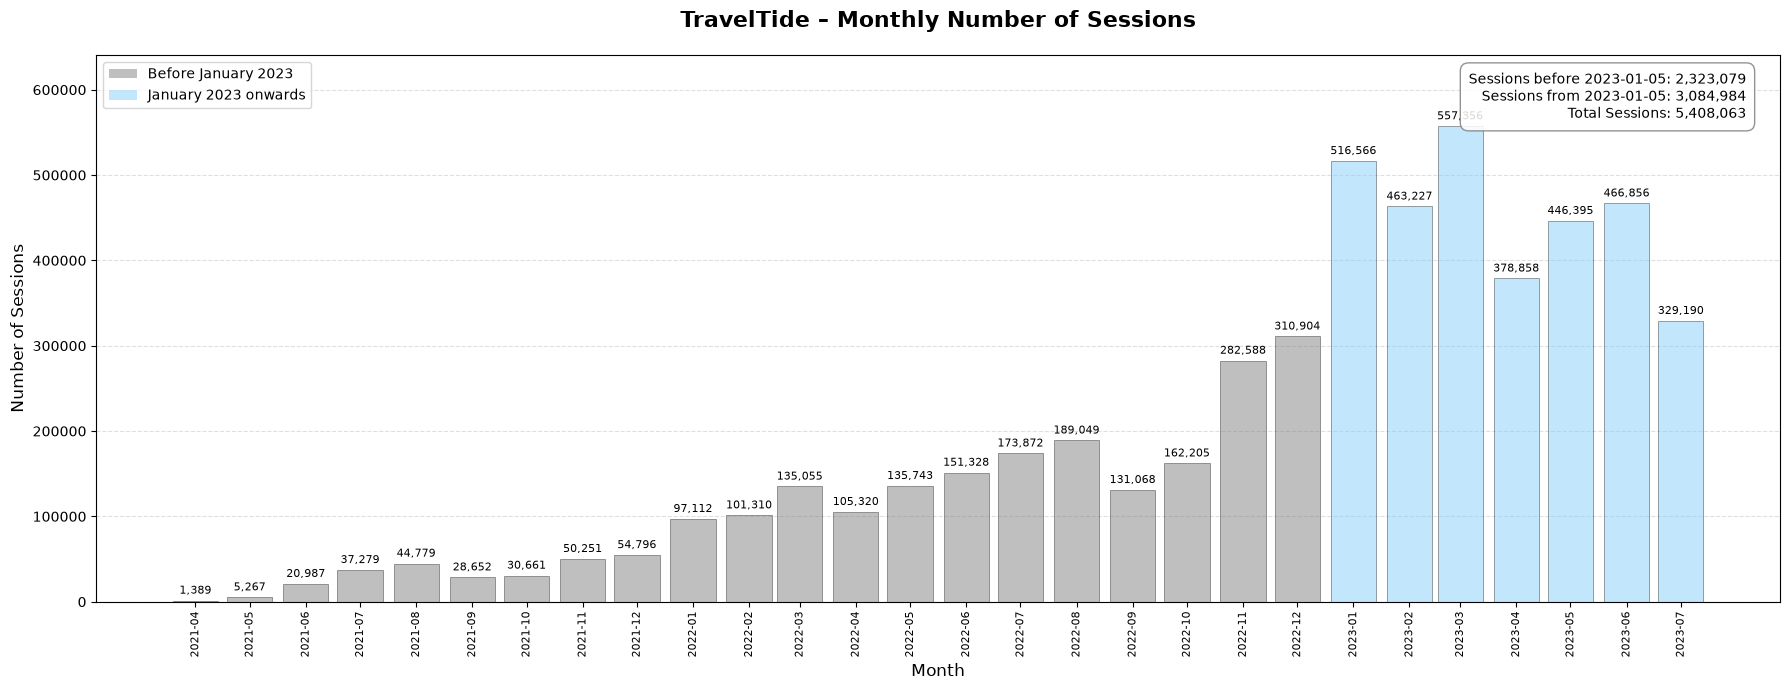

In [92]:

# 4.4. Monthly Session Activity

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch

# Convert session_start to datetime
sessions["session_start"] = pd.to_datetime(
    sessions["session_start"],
    errors="coerce"
)

# Remove records without valid session_start
valid_sessions = sessions.dropna(
    subset=["session_start"]
).copy()

# Aggregate sessions by month
monthly_sessions = (
    valid_sessions
    .set_index("session_start")
    .resample("MS")
    .size()
)

# Create complete monthly timeline
monthly_sessions = monthly_sessions.asfreq(
    "MS",
    fill_value=0
)

# Define analysis cutoff date
cutoff_date = pd.Timestamp("2023-01-05")  

# Calculate sessions before and from cutoff date
sessions_before = (
    valid_sessions["session_start"] < cutoff_date
).sum()

sessions_after = (
    valid_sessions["session_start"] >= cutoff_date
).sum()

total_sessions = sessions_before + sessions_after

# Assign colors based on monthly period
bar_colors = [
    "grey" if date < cutoff_date.replace(day=1)
    else "lightskyblue"
    for date in monthly_sessions.index
]

# Display monthly summary
monthly_summary = monthly_sessions.rename(
    "Number of Sessions"
).to_frame()

print("=" * 70)
print("TRAVELTIDE – MONTHLY SESSION ACTIVITY")
print("=" * 70)

print(f"First session: {valid_sessions['session_start'].min()}")
print(f"Last session:  {valid_sessions['session_start'].max()}")
print(f"Total sessions: {len(valid_sessions):,}")
print(f"Total months: {len(monthly_sessions)}")

display(monthly_summary)

# Display period comparison
print("\nSESSION PERIOD COMPARISON")
print("-" * 70)
print(f"Sessions before 2023-01-05: {sessions_before:,}")
print(f"Sessions from 2023-01-05:   {sessions_after:,}")
print(f"Total sessions:             {total_sessions:,}")

# Create bar chart
fig, ax = plt.subplots(figsize=(18, 7))

bars = ax.bar(
    monthly_sessions.index,
    monthly_sessions.values,
    width=25,
    color=bar_colors,
    alpha=0.5,
    edgecolor="black",
    linewidth=0.5
)

# Add session counts above every bar
ax.bar_label(
    bars,
    labels=[f"{value:,}" for value in monthly_sessions.values],
    padding=3,
    fontsize=8
)

# Chart title and labels
ax.set_title(
    "TravelTide – Monthly Number of Sessions",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel("Number of Sessions", fontsize=12)

# Display every month on the x-axis
ax.set_xticks(monthly_sessions.index)
ax.set_xticklabels(
    monthly_sessions.index.strftime("%Y-%m"),
    rotation=90,
    fontsize=8
)

# Add horizontal grid
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

ax.set_axisbelow(True)

# Add legend
legend_elements = [
    Patch(
        facecolor="grey",
        alpha=0.5,
        label="Before January 2023"
    ),
    Patch(
        facecolor="lightskyblue",
        alpha=0.5,
        label="January 2023 onwards"
    )
]

ax.legend(handles=legend_elements, loc="upper left")

# Add total session counts to chart
summary_text = (
    f"Sessions before 2023-01-05: {sessions_before:,}\n"
    f"Sessions from 2023-01-05: {sessions_after:,}\n"
    f"Total Sessions: {total_sessions:,}"
)

ax.text(
    0.98,
    0.97,
    summary_text,
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="top",
    horizontalalignment="right",
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="white",
        edgecolor="grey",
        alpha=0.85
    )
)

# Improve layout
ax.set_ylim(
    0,
    max(monthly_sessions.max() * 1.15, 1)
)

plt.tight_layout()
plt.show()


In [93]:
# Define analysis cutoff date
cutoff_date = pd.Timestamp("2023-01-05") # Set cutoff time to 2023-01-05 00:00:00 for session period comparison

# Calculate total sessions before and from cutoff date
sessions_before = (
    valid_sessions["session_start"] < cutoff_date
).sum()

sessions_after = (
    valid_sessions["session_start"] >= cutoff_date
).sum()

# Calculate total sessions
total_sessions = sessions_before + sessions_after

print("SESSION PERIOD COMPARISON")
print("-" * 50)
print(f"Sessions before 2023-01-05: {sessions_before:,}")
print(f"Sessions from 2023-01-05:   {sessions_after:,}")
print(f"Total sessions:             {total_sessions:,}")


SESSION PERIOD COMPARISON
--------------------------------------------------
Sessions before 2023-01-05: 2,323,079
Sessions from 2023-01-05:   3,084,984
Total sessions:             5,408,063


## 4.5. Daily Session Activity – January 2023

This section examines the daily distribution of sessions throughout January 2023.

The objective is to analyze daily platform activity and identify changes in session volume around January 4, 2023.

TRAVELTIDE – DAILY SESSION ACTIVITY – JANUARY 2023
Total sessions in January: 516,566
Days analyzed: 31


,Number of Sessions
session_start,
2023-01-01,18649
2023-01-02,18678
2023-01-03,18270
2023-01-04,17867
2023-01-05,17612
2023-01-06,17203
2023-01-07,17172
2023-01-08,16702
2023-01-09,17013



SESSION PERIOD COMPARISON
----------------------------------------------------------------------
January 1–4:  73,464
January 5–31: 443,102
Total:        516,566


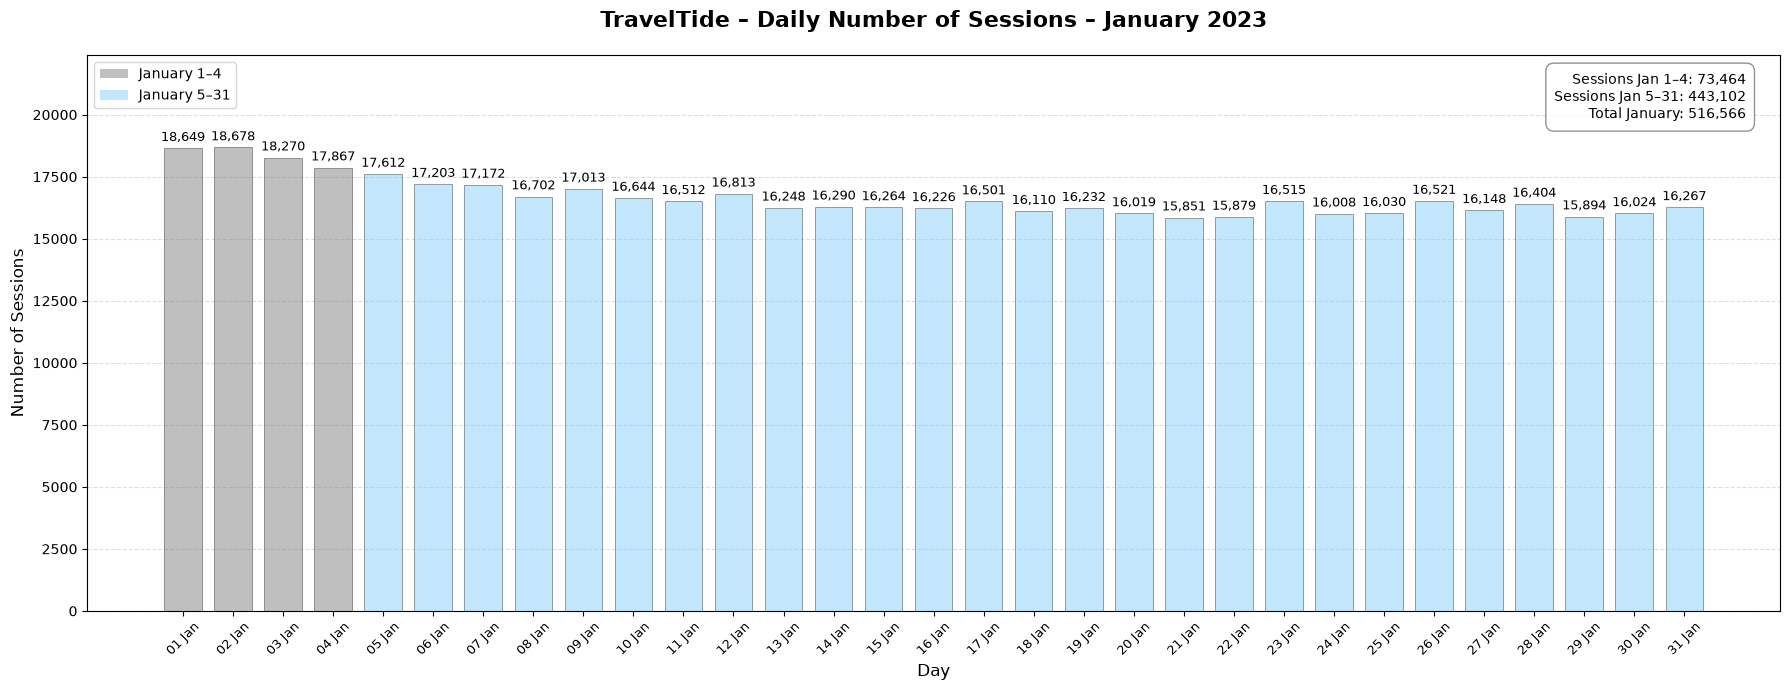

In [94]:
# 4.5. Daily Session Activity – January 2023

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Define analysis period
start_date = pd.Timestamp("2023-01-01")
end_date = pd.Timestamp("2023-02-01")
cutoff_date = pd.Timestamp("2023-01-04") # the count is for every day.

# Filter January 2023 sessions
january_sessions = valid_sessions[
    (valid_sessions["session_start"] >= start_date) &
    (valid_sessions["session_start"] < end_date)
].copy()

# Aggregate sessions by day
daily_sessions = (
    january_sessions
    .set_index("session_start")
    .resample("D")
    .size()
)

# Create complete daily timeline
daily_sessions = daily_sessions.asfreq(
    "D",
    fill_value=0
)

# Assign colors
bar_colors = [
    "grey" if date <= cutoff_date else "lightskyblue"
    for date in daily_sessions.index
]

# Display daily summary
daily_summary = daily_sessions.rename(
    "Number of Sessions"
).to_frame()

print("=" * 70)
print("TRAVELTIDE – DAILY SESSION ACTIVITY – JANUARY 2023")
print("=" * 70)

print(f"Total sessions in January: {daily_sessions.sum():,}")
print(f"Days analyzed: {len(daily_sessions)}")

display(daily_summary)

# Calculate period totals
sessions_before = daily_sessions[
    daily_sessions.index <= cutoff_date
].sum()

sessions_after = daily_sessions[
    daily_sessions.index > cutoff_date
].sum()

print("\nSESSION PERIOD COMPARISON")
print("-" * 70)
print(f"January 1–4:  {sessions_before:,}")
print(f"January 5–31: {sessions_after:,}")
print(f"Total:        {daily_sessions.sum():,}")

# Create bar chart
fig, ax = plt.subplots(figsize=(18, 7))

bars = ax.bar(
    daily_sessions.index,
    daily_sessions.values,
    width=0.75,
    color=bar_colors,
    alpha=0.5,
    edgecolor="black",
    linewidth=0.5
)

# Add session counts above every bar
ax.bar_label(
    bars,
    labels=[f"{value:,}" for value in daily_sessions.values],
    padding=3,
    fontsize=9
)

# Chart title and labels
ax.set_title(
    "TravelTide – Daily Number of Sessions – January 2023",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Day", fontsize=12)
ax.set_ylabel("Number of Sessions", fontsize=12)

# Display every day on the x-axis
ax.set_xticks(daily_sessions.index)
ax.set_xticklabels(
    daily_sessions.index.strftime("%d Jan"),
    rotation=45,
    fontsize=9
)

# Add horizontal grid
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

ax.set_axisbelow(True)

# Add legend
legend_elements = [
    Patch(
        facecolor="grey",
        alpha=0.5,
        label="January 1–4"
    ),
    Patch(
        facecolor="lightskyblue",
        alpha=0.5,
        label="January 5–31"
    )
]

ax.legend(handles=legend_elements, loc="upper left")

# Add period totals to chart
summary_text = (
    f"Sessions Jan 1–4: {sessions_before:,}\n"
    f"Sessions Jan 5–31: {sessions_after:,}\n"
    f"Total January: {daily_sessions.sum():,}"
)

ax.text(
    0.98,
    0.97,
    summary_text,
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="top",
    horizontalalignment="right",
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="white",
        edgecolor="grey",
        alpha=0.85
    )
)

# Improve layout
ax.set_ylim(
    0,
    max(daily_sessions.max() * 1.20, 1)
)

plt.tight_layout()
plt.show()


## 4.6. Remove Invalid and Unwanted Session Records

### Objective

Clean the working dataset by identifying and removing session records that do not meet the data quality and analysis requirements.

All removed records will be preserved in a separate CSV file named `rem_sessions.csv` for documentation and potential future analysis.

### Removal Criteria

Four groups of records will be identified for removal:

1. **Invalid timestamps:** Remove all records with a missing or invalid `session_start` timestamp.

2. **Sessions before January 5, 2023:** Remove all records with a valid `session_start` timestamp earlier than January 5, 2023, at 00:00:00.

3. **Zero page clicks:** Remove all records where `page_clicks = 0`.

4. **Low page-click activity:** Remove all records where `page_clicks` is between 1 and 7, inclusive.

### Data Handling Procedure

The removal process follows these steps:

1. **Identify removal groups:** Apply the four removal criteria to the working dataset.

2. **Count records:** Calculate the number of records in each group and display the individual counts and total number of records to be removed before making any changes.

3. **Avoid duplicate counting:** Assign each record to only one removal group, following the order of the criteria listed above. This ensures that records meeting multiple conditions are counted and exported only once.

4. **Export removed records:** Copy all identified records, including all original columns and values, into `rem_sessions.csv`.

5. **Update the working dataset:** Delete all exported records from the working DataFrame `sessions`.

6. **Verify the results:** Confirm that:
   - All removed records have been exported successfully.
   - No invalid timestamps remain.
   - No sessions before January 5, 2023, remain.
   - No records with zero page clicks remain.
   - No records with between 1 and 7 page clicks remain.
   - The number of exported records matches the total number identified for removal.

### Expected Result

- **`rem_sessions.csv`:** Contains all records removed according to the four criteria, with their original columns and values preserved.
- **Working dataset (`sessions`):** Contains only valid session records from January 5, 2023, onwards, with at least 8 page clicks.
- **Data integrity:** Each removed record is exported only once, and the original CSV file on disk remains unchanged.

This procedure ensures that the working dataset meets the defined temporal and activity requirements while preserving all excluded records separately for traceability and potential future analysis.

In [95]:
# 4.6. Remove Invalid and Unwanted Session Records

import pandas as pd

# Define cutoff date and output file
cutoff_date = pd.Timestamp("2023-01-05")
rem_sessions_path = WORKING_DIR / "rem_sessions.csv"

# Convert columns for validation without changing the original data
session_dates = pd.to_datetime(
    sessions["session_start"],
    errors="coerce"
)

page_clicks = pd.to_numeric(
    sessions["page_clicks"],
    errors="coerce"
)

# Identify removal groups (each row can belong to only one group)
invalid_timestamp = session_dates.isna()

before_cutoff = (
    ~invalid_timestamp &
    (session_dates < cutoff_date)
)

page_clicks_zero = (
    ~invalid_timestamp &
    (session_dates >= cutoff_date) &
    (page_clicks == 0)
)

page_clicks_one_to_seven = (
    ~invalid_timestamp &
    (session_dates >= cutoff_date) &
    (page_clicks >= 1) &
    (page_clicks <= 7)
)

# Count records in each group BEFORE removal
count_invalid = invalid_timestamp.sum()
count_before = before_cutoff.sum()
count_zero = page_clicks_zero.sum()
count_one_to_seven = page_clicks_one_to_seven.sum()

total_to_remove = (
    count_invalid +
    count_before +
    count_zero +
    count_one_to_seven
)

# Display removal counts
print("=" * 65)
print("SESSION DATA REMOVAL – RECORD COUNTS")
print("=" * 65)
print(f"Invalid session timestamps:       {count_invalid:,}")
print(f"Sessions before 2023-01-05:       {count_before:,}")
print(f"Sessions with page_clicks = 0:    {count_zero:,}")
print(f"Sessions with page_clicks 1–7:    {count_one_to_seven:,}")
print("-" * 65)
print(f"TOTAL RECORDS TO REMOVE:          {total_to_remove:,}")
print(f"Original working dataset:         {len(sessions):,}")

# Combine all removal conditions
remove_mask = (
    invalid_timestamp |
    before_cutoff |
    page_clicks_zero |
    page_clicks_one_to_seven
)

# Copy all selected records
sessions_to_remove = sessions.loc[remove_mask].copy()

# Export removed records to CSV
sessions_to_remove.to_csv(
    rem_sessions_path,
    index=False
)

# Delete selected records from working dataset
sessions = sessions.loc[~remove_mask].copy()

# Verify results
print("\n" + "=" * 65)
print("REMOVAL VERIFICATION")
print("=" * 65)
print(f"Records exported to rem_sessions.csv: {len(sessions_to_remove):,}")
print(f"Records remaining in working dataset: {len(sessions):,}")
print(f"Records removed:                      {len(sessions_to_remove):,}")
print(f"Removal file: {rem_sessions_path}")

# Check that all removal conditions are satisfied
remaining_dates = pd.to_datetime(
    sessions["session_start"],
    errors="coerce"
)

remaining_clicks = pd.to_numeric(
    sessions["page_clicks"],
    errors="coerce"
)

assert remaining_dates.notna().all(), "Invalid timestamps remain!"
assert not (remaining_dates < cutoff_date).any(), "Sessions before cutoff remain!"
assert not (remaining_clicks == 0).any(), "Sessions with zero page clicks remain!"
assert not (
    remaining_clicks.between(1, 7, inclusive="both")
).any(), "Sessions with 1–7 page clicks remain!"

assert len(sessions_to_remove) == total_to_remove, "Removal count mismatch!"

print("\nAll verification checks passed successfully.")

SESSION DATA REMOVAL – RECORD COUNTS
Invalid session timestamps:       0
Sessions before 2023-01-05:       2,323,079
Sessions with page_clicks = 0:    1
Sessions with page_clicks 1–7:    832,894
-----------------------------------------------------------------
TOTAL RECORDS TO REMOVE:          3,155,974
Original working dataset:         5,408,063

REMOVAL VERIFICATION
Records exported to rem_sessions.csv: 3,155,974
Records remaining in working dataset: 2,252,089
Records removed:                      3,155,974
Removal file: d:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\working\rem_sessions.csv

All verification checks passed successfully.


## 4.7. Identify, Check and Convert Binary Columns

### Objective

Identify all binary columns in the working dataset `sessions`, check their data quality, and convert columns containing only `t` and `f` values into Boolean data types (`True` and `False`).

### Data Processing Procedure

1. **Identify binary columns:** Find all columns containing exactly two distinct non-null values.

2. **Check missing values:** Examine the identified columns for missing (`NaN`) values and report the number of missing entries in each column.

3. **Analyze binary value distributions:** Count the occurrences of `t` and `f` in each identified column before conversion.

4. **Validate column contents:** Check whether the identified columns contain exclusively `t` and `f` values, ignoring missing values. Columns containing other values are excluded from conversion and reported with a warning.

5. **Convert binary values:** Convert valid `t` and `f` columns into Boolean values:
   - `t` becomes `True`
   - `f` becomes `False`
   - Missing values remain missing (`<escape><NA></escape>`).

6. **Verify conversion:** Calculate the number of `True` and `False` values after conversion and compare these counts with the original distribution.

7. **Display results:** Generate a summary table showing the original total counts, the numbers of `True` and `False` values, and the number of successfully converted entries for each column.

### Expected Result

- Binary columns are identified systematically.
- Missing values are documented.
- Valid `t`/`f` columns are converted to Boolean data types.
- Columns containing unexpected values remain unchanged and are reported.
- The resulting summary table provides an overview of the conversion and supports data quality verification.

This step standardizes binary variables and prepares them for consistent analysis in subsequent stages of the TravelTide data exploration.

In [96]:
# 4.7.Find, Check and Convert Binary Columns

import pandas as pd

# 1. Find all columns with exactly two unique values
binary_columns = []

for col in sessions.columns:
    if sessions[col].nunique(dropna=True) == 2:
        binary_columns.append(col)

print("BINARY COLUMNS FOUND")
print("-" * 60)
print(f"Number of columns found: {len(binary_columns)}")

# 2. Check whether the identified columns contain NaN
nan_columns = []

for col in binary_columns:
    nan_count = sessions[col].isna().sum()

    if nan_count > 0:
        nan_columns.append(col)

    print(
        f"{col}: NaN contained = {'YES' if nan_count > 0 else 'NO'} "
        f"({nan_count:,} NaN values)"
    )

print("\nColumns containing NaN:")
print(nan_columns if nan_columns else "None")

# 3. Create a table with the original t/f counts
boolean_counts = pd.DataFrame(index=["Total", "True", "False", "Changes"])

for col in binary_columns:
    values = sessions[col].astype("string").str.strip().str.lower()

    t_count = (values == "t").sum()
    f_count = (values == "f").sum()

    # Total number of t and f values before conversion
    total_count = t_count + f_count

    # Only convert columns containing exclusively t/f (ignoring NaN)
    if values.dropna().isin(["t", "f"]).all():
        sessions[col] = values.map({"t": True, "f": False}).astype("boolean")

        true_count = (sessions[col] == True).sum()
        false_count = (sessions[col] == False).sum()

        # Number of values successfully converted
        changes = true_count + false_count

        boolean_counts.loc["Total", col] = total_count
        boolean_counts.loc["True", col] = true_count
        boolean_counts.loc["False", col] = false_count
        boolean_counts.loc["Changes", col] = changes

    else:
        print(
            f"WARNING: Column '{col}' was not converted. "
            "It contains values other than t/f."
        )

# 4. Remove columns that were not converted
boolean_counts = boolean_counts.dropna(axis=1, how="all")

# 5. Format table
boolean_counts = boolean_counts.fillna(0).astype(int)

print("\nBOOLEAN VALUE DISTRIBUTION")
display(boolean_counts.style.format("{:,}"))


BINARY COLUMNS FOUND
------------------------------------------------------------
Number of columns found: 5
flight_discount: NaN contained = NO (0 NaN values)
hotel_discount: NaN contained = NO (0 NaN values)
flight_booked: NaN contained = NO (0 NaN values)
hotel_booked: NaN contained = NO (0 NaN values)
cancellation: NaN contained = NO (0 NaN values)

Columns containing NaN:
None

BOOLEAN VALUE DISTRIBUTION


,flight_discount,hotel_discount,flight_booked,hotel_booked,cancellation
Total,"2,252,089","2,252,089","2,252,089","2,252,089","2,252,089"
True,"412,037","348,278","1,138,308","1,148,253","54,378"
False,"1,840,052","1,903,811","1,113,781","1,103,836","2,197,711"
Changes,"2,252,089","2,252,089","2,252,089","2,252,089","2,252,089"


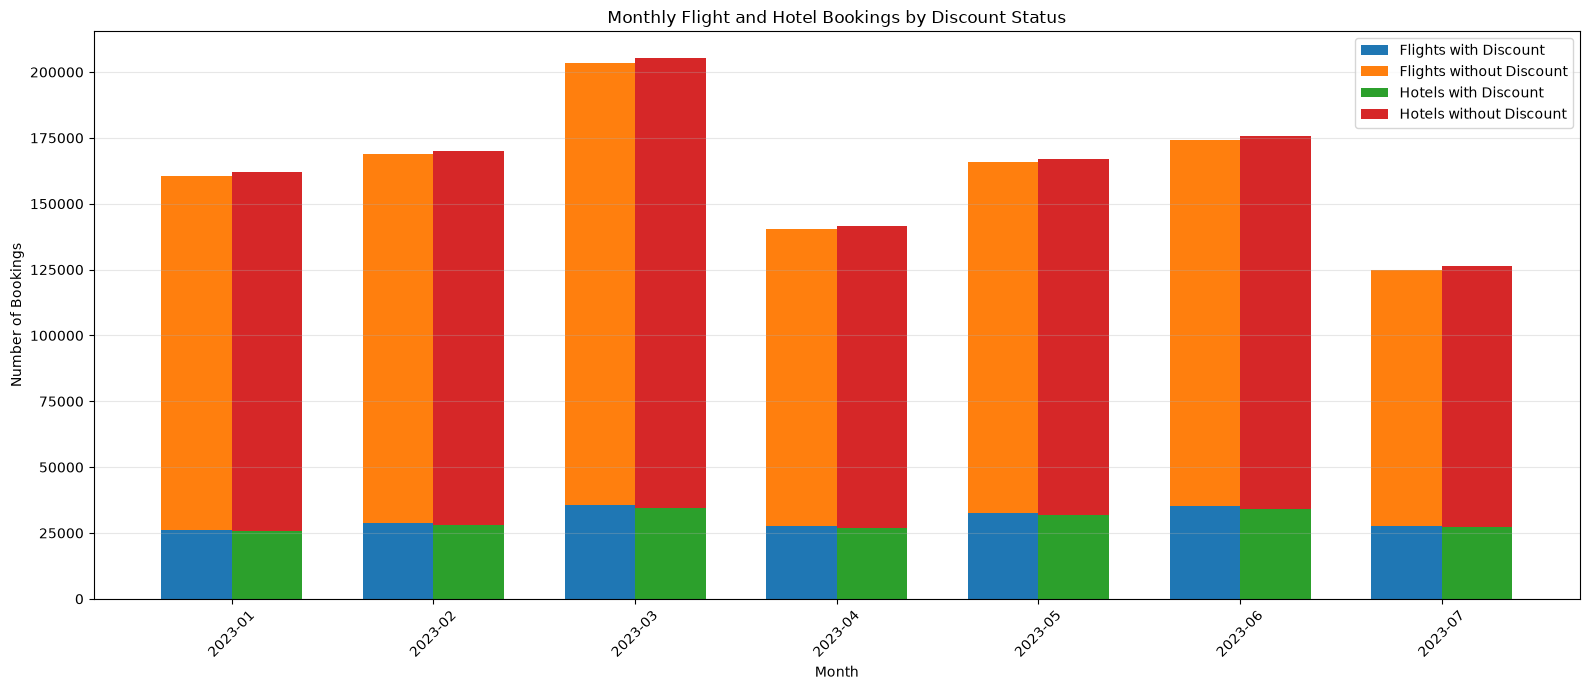

,Flights_With_Discount,Flights_Without_Discount,Hotels_With_Discount,Hotels_Without_Discount
month,,,,
2023-01,26267,134328,25823,136161
2023-02,28819,140065,28034,142185
2023-03,35798,167652,34509,170695
2023-04,27611,112923,26729,114923
2023-05,32464,133295,31856,135213
2023-06,35079,139047,34125,141543
2023-07,27794,97166,27264,99193


In [99]:
# 4.8. Monthly Flight and Hotel Bookings by Discount Status

x = np.arange(len(monthly_bookings))
width = 0.35

fig, ax = plt.subplots(figsize=(16, 7))

# Flight bookings (stacked)
ax.bar(
    x - width / 2,
    monthly_bookings["Flights_With_Discount"],
    width,
    label="Flights with Discount"
)
ax.bar(
    x - width / 2,
    monthly_bookings["Flights_Without_Discount"],
    width,
    bottom=monthly_bookings["Flights_With_Discount"],
    label="Flights without Discount"
)

# Hotel bookings (stacked)
ax.bar(
    x + width / 2,
    monthly_bookings["Hotels_With_Discount"],
    width,
    label="Hotels with Discount"
)
ax.bar(
    x + width / 2,
    monthly_bookings["Hotels_Without_Discount"],
    width,
    bottom=monthly_bookings["Hotels_With_Discount"],
    label="Hotels without Discount"
)

ax.set_title("Monthly Flight and Hotel Bookings by Discount Status")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Bookings")
ax.set_xticks(x)
ax.set_xticklabels(monthly_bookings.index.astype(str), rotation=45)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

display(monthly_bookings)